# Does the protein agree with the pathology report?

Breast tumors are tested for estrogen receptor (ER) in the clinic. TCGA *also* measured ER-alpha protein directly. **Do the two agree, for which tumors, and does the answer change depending on which samples you include?**

That's the kind of question every product in this challenge has to handle: real data from different sources, joined by IDs, where each join changes who is in the cohort.

*Research only: no diagnosis, treatment advice or clinical claims.*

## 1 · Get the data (about 10 seconds)
Downloads the TCGA-BRCA files from the public UCSC Xena hub and checks each against the event's frozen checksums. Works from a clone of the repo or in Colab.

In [1]:
import pathlib, subprocess, sys, urllib.request
REPO = "https://raw.githubusercontent.com/disleveK/oncosys-hackathon-challenge/main/"
here = next((p for p in [pathlib.Path("."), pathlib.Path("..")] if (p / "data/tcga-brca/fetch.py").exists()), None)
if here is None:                                   # Colab: fetch the small helper files first
    here = pathlib.Path("."); d = here / "data/tcga-brca"; d.mkdir(parents=True, exist_ok=True)
    for f in ["fetch.py", "sources.csv", "sample_manifest.csv", "slide_manifest.csv", "reference_analyses.py"]:
        urllib.request.urlretrieve(REPO + "data/tcga-brca/" + f, d / f)
DATA = here / "data/tcga-brca"
_ = subprocess.run([sys.executable, str(DATA / "fetch.py"), "--no-rna"], check=True)

ok     clinical.tsv
ok     survival.tsv
ok     mutation_gene_level.tsv.gz
ok     protein_rppa.tsv.gz
ok     copy_number_gistic.tsv.gz
skip   rna_hiseq.tsv.gz


## 2 · What does one row mean?
`sample_manifest.csv` has one row per **sample**. A patient can have more than one (a tumor and a normal-tissue sample, for example). The `has_*` columns say which data layers exist for that sample.

In [2]:
import pandas as pd
samples = pd.read_csv(DATA / "sample_manifest.csv")
print(samples.sample_type.value_counts().to_string(), "\n")
samples.head()

sample_type
Primary Tumor          1101
Solid Tissue Normal     139
Metastatic                7 



,sample_id,patient_id,sample_type,in_clinical,has_survival,has_mutation,has_copy_number,has_rna,has_protein,slides_for_sample
0,TCGA-3C-AAAU-01,TCGA-3C-AAAU,Primary Tumor,True,True,True,True,True,False,1
1,TCGA-3C-AALI-01,TCGA-3C-AALI,Primary Tumor,True,True,True,True,True,False,3
2,TCGA-3C-AALJ-01,TCGA-3C-AALJ,Primary Tumor,True,True,True,True,True,False,3
3,TCGA-3C-AALK-01,TCGA-3C-AALK,Primary Tumor,True,True,True,True,True,False,2
4,TCGA-4H-AAAK-01,TCGA-4H-AAAK,Primary Tumor,True,True,True,True,True,False,2


## 3 · Every join changes the cohort
Start with primary tumors and add one data layer at a time.

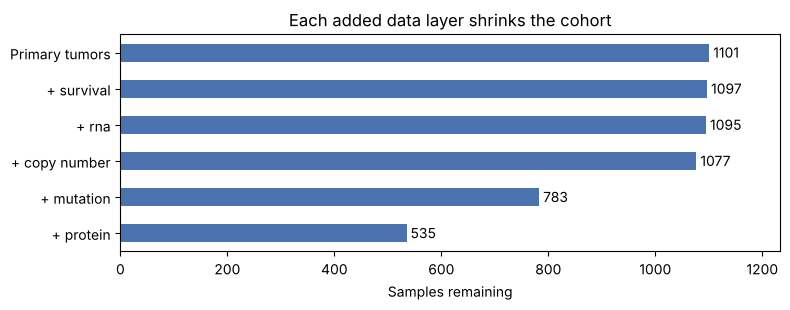

In [3]:
import matplotlib.pyplot as plt
steps, cohort = [], samples[samples.sample_type == "Primary Tumor"]
steps.append(("Primary tumors", len(cohort)))
for layer in ["has_survival", "has_rna", "has_copy_number", "has_mutation", "has_protein"]:
    cohort = cohort[cohort[layer]]
    steps.append(("+ " + layer.replace("has_", "").replace("_", " "), len(cohort)))
labels, counts = zip(*steps)
ax = pd.Series(counts, index=labels).plot.barh(color="#4C72B0", figsize=(8, 3.2))
ax.invert_yaxis(); ax.set_xlabel("Samples remaining"); ax.set_title("Each added data layer shrinks the cohort")
for i, n in enumerate(counts):
    ax.annotate(f" {n}", (n, i), va="center")
ax.set_xlim(0, max(counts) * 1.12); plt.tight_layout(); plt.show()

## 4 · Join clinical ER status to ER-alpha protein

In [4]:
clinical = pd.read_csv(DATA / "raw/clinical.tsv", sep="\t", low_memory=False)
protein = pd.read_csv(DATA / "raw/protein_rppa.tsv.gz", sep="\t", index_col=0)
er = clinical.set_index("sampleID")["breast_carcinoma_estrogen_receptor_status"]
tumors = [s for s in protein.columns if s[13:15] == "01" and er.get(s) in ("Positive", "Negative")]
df = pd.DataFrame({"sample_id": tumors, "er_ihc": [er[s] for s in tumors],
                   "er_alpha_protein": protein.loc["ERALPHA", tumors].values})
df.groupby("er_ihc").er_alpha_protein.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
er_ihc,,,,,,,,
Negative,169.0,-0.87,0.86,-2.03,-1.41,-1.07,-0.68,2.96
Positive,529.0,2.18,1.29,-1.69,1.45,2.31,3.15,4.97


## 5 · Look at the tissue
Every slide opens in the browser through NCI Imaging Data Commons. No download needed.

In [5]:
slides = pd.read_csv(DATA / "slide_manifest.csv")
example = slides[(slides.sample_id == df.sample_id.iloc[0]) & (slides.slide_kind == "diagnostic (FFPE)")]
example[["slide_barcode", "slide_kind", "viewer_url"]]

,slide_barcode,slide_kind,viewer_url
28,TCGA-A1-A0SF-01Z-00-DX1,diagnostic (FFPE),https://viewer.imaging.datacommons.cancer.gov/...


## Your turn
Pick a product from [`products/`](../products/README.md). Some questions this data raises right away:
- Which tumors disagree between the clinical test and the protein measurement, and what else do we know about them?
- Do your conclusions hold if you change which samples are included?
- What happens to your tool when a new release changes some samples? Build one with `python data/tcga-brca/make_release.py`.